# Day 16 SwiGLU MLP

In [1]:
!apt-get install -y -qq nsight-compute-2026.3.1 > /dev/null

import os
os.environ["PATH"] += ":/opt/nvidia/nsight-compute/2026.3.1"

In [2]:
%%writefile swiglu_kernels.py
import torch, triton, triton.language as tl

DEVICE = triton.runtime.driver.active.get_active_torch_device()
DTYPE = torch.float16
D, FF = 2048, 5632


def make_weights():
    w_gate = torch.randn(D, FF, device=DEVICE, dtype=DTYPE) * 0.02
    w_up   = torch.randn(D, FF, device=DEVICE, dtype=DTYPE) * 0.02
    w_down = torch.randn(FF, D, device=DEVICE, dtype=DTYPE) * 0.02

    return w_gate, w_up, w_down


def swiglu_unfused(x, w_gate, w_up, w_down):
    g = x @ w_gate
    u = x @ w_up
    a = torch.nn.functional.silu(g)
    h = a * u
    return h @ w_down


@triton.jit
def gate_up_silu_kernel(x_ptr, wg_ptr, wu_ptr, h_ptr, M, N, K,
                        stride_xm, stride_xk, stride_wk, stride_wn,
                        stride_hm, stride_hn,
                        BLOCK_M: tl.constexpr, BLOCK_N: tl.constexpr,
                        BLOCK_K: tl.constexpr):
    pid_m = tl.program_id(0)
    pid_n = tl.program_id(1)

    offs_m = pid_m * BLOCK_M + tl.arange(0, BLOCK_M)
    offs_n = pid_n * BLOCK_N + tl.arange(0, BLOCK_N)
    offs_k = tl.arange(0, BLOCK_K)

    x_ptrs  = x_ptr  + offs_m[:, None] * stride_xm + offs_k[None, :] * stride_xk
    wg_ptrs = wg_ptr + offs_k[:, None] * stride_wk + offs_n[None, :] * stride_wn
    wu_ptrs = wu_ptr + offs_k[:, None] * stride_wk + offs_n[None, :] * stride_wn

    acc_g = tl.zeros((BLOCK_M, BLOCK_N), dtype=tl.float32)
    acc_u = tl.zeros((BLOCK_M, BLOCK_N), dtype=tl.float32)

    for k in range(0, tl.cdiv(K, BLOCK_K)):
        k_mask = offs_k < K - k * BLOCK_K

        x  = tl.load(x_ptrs,  mask=(offs_m[:, None] < M) & k_mask[None, :], other=0.0)
        wg = tl.load(wg_ptrs, mask=k_mask[:, None] & (offs_n[None, :] < N), other=0.0)
        wu = tl.load(wu_ptrs, mask=k_mask[:, None] & (offs_n[None, :] < N), other=0.0)

        acc_g += tl.dot(x, wg)
        acc_u += tl.dot(x, wu)

        x_ptrs  += BLOCK_K * stride_xk
        wg_ptrs += BLOCK_K * stride_wk
        wu_ptrs += BLOCK_K * stride_wk

    h = acc_g * tl.sigmoid(acc_g) * acc_u

    h_ptrs = h_ptr + offs_m[:, None] * stride_hm + offs_n[None, :] * stride_hn

    tl.store(h_ptrs, h.to(h_ptr.dtype.element_ty), mask=(offs_m[:, None] < M) & (offs_n[None, :] < N))


def gate_up_silu(x, w_gate, w_up, BM=64, BN=64, BK=32):

    assert w_gate.shape == w_up.shape and w_gate.stride() == w_up.stride()

    M, K = x.shape
    N = w_gate.shape[1]

    h = torch.empty((M, N), device=x.device, dtype=x.dtype)

    grid = (triton.cdiv(M, BM), triton.cdiv(N, BN))

    gate_up_silu_kernel[grid](x, w_gate, w_up, h, M, N, K,
                              x.stride(0), x.stride(1),
                              w_gate.stride(0), w_gate.stride(1),
                              h.stride(0), h.stride(1),
                              BLOCK_M=BM, BLOCK_N=BN, BLOCK_K=BK,
                              num_warps=4, num_stages=3)
    return h


def swiglu_fused(x, w_gate, w_up, w_down):
    return gate_up_silu(x, w_gate, w_up) @ w_down

Writing swiglu_kernels.py


In [3]:
import importlib, torch, triton
import swiglu_kernels
importlib.reload(swiglu_kernels)
from swiglu_kernels import *

In [4]:
torch.manual_seed(0)

w_gate, w_up, w_down = make_weights()

for M in [1, 17, 128, 1000]:
    x = torch.randn(M, D, device=DEVICE, dtype=DTYPE)
    ref = swiglu_unfused(x, w_gate, w_up, w_down)
    out = swiglu_fused(x, w_gate, w_up, w_down)
    assert torch.allclose(out, ref, atol=1e-2, rtol=1e-2), (M, (out - ref).abs().max())

print("all match")

all match


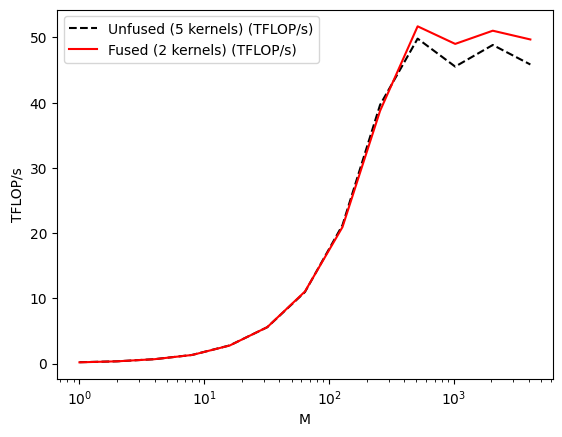

swiglu-fusion:
         M  Unfused (5 kernels) (TFLOP/s)  Fused (2 kernels) (TFLOP/s)
0      1.0                       0.197288                     0.181685
1      2.0                       0.334597                     0.334105
2      4.0                       0.663665                     0.662370
3      8.0                       1.316631                     1.310000
4     16.0                       2.776290                     2.763233
5     32.0                       5.571455                     5.580458
6     64.0                      10.953270                    11.030320
7    128.0                      21.218241                    20.918334
8    256.0                      39.641371                    38.732264
9    512.0                      49.814164                    51.700173
10  1024.0                      45.524702                    49.004294
11  2048.0                      48.839814                    51.027478
12  4096.0                      45.848065                    4

In [5]:
@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=['M'], x_vals=[2**i for i in range(0, 13)], x_log=True,
        line_arg='provider',
        line_vals=['unfused', 'fused'],
        line_names=['Unfused (5 kernels)', 'Fused (2 kernels)'],
        styles=[('black', '--'), ('red', '-')],
        ylabel='TFLOP/s', plot_name='swiglu-fusion', args={},
    )
)

def bench(M, provider):
    x = torch.randn(M, D, device=DEVICE, dtype=DTYPE)

    fn = swiglu_unfused if provider == 'unfused' else swiglu_fused

    ms = triton.testing.do_bench(lambda: fn(x, w_gate, w_up, w_down))

    flops = 2 * M * D * FF * 3

    return flops / (ms * 1e-3) * 1e-12

bench.run(print_data=True, show_plots=True)

In [6]:
%%writefile swiglu_prof.py

import sys, torch
from swiglu_kernels import *

impl, M = sys.argv[1], int(sys.argv[2])

torch.manual_seed(0)

w_gate, w_up, w_down = make_weights()

x = torch.randn(M, D, device=DEVICE, dtype=DTYPE)

fn = swiglu_unfused if impl == 'unfused' else swiglu_fused

fn(x, w_gate, w_up, w_down); torch.cuda.synchronize()

torch.cuda.cudart().cudaProfilerStart()

fn(x, w_gate, w_up, w_down); torch.cuda.synchronize()

torch.cuda.cudart().cudaProfilerStop()

Writing swiglu_prof.py


In [7]:
import subprocess, io
import pandas as pd

METRICS = ",".join([
    "dram__bytes_read.sum", "dram__bytes_write.sum",
    "lts__t_bytes.sum", "gpu__time_duration.sum",
])

TIME_UNIT = {"nsecond": 1e-9, "ns": 1e-9, "usecond": 1e-6, "us": 1e-6,
             "msecond": 1e-3, "ms": 1e-3, "second": 1.0, "s": 1.0}

def profile(impl, M, extra=()):

    log = f"/tmp/swiglu_{impl}_{M}.csv"

    cmd = ["ncu", "--profile-from-start", "off", "--clock-control", "none",
           "--csv", "--page", "raw", "--print-units", "base",
           "--log-file", log, "--metrics", METRICS, *extra,
           "python", "swiglu_prof.py", impl, str(M)]

    r = subprocess.run(cmd, capture_output=True, text=True)

    if r.returncode != 0:
        print(r.stdout[-2000:], r.stderr[-2000:])
        r.check_returncode()

    lines = [l for l in open(log) if l.startswith('"')]
    raw = pd.read_csv(io.StringIO("".join(lines)))
    units, df = raw.iloc[0], raw.iloc[1:]

    num = lambda c: pd.to_numeric(df[c].astype(str).str.replace(",", ""), errors="coerce").sum()

    dram = num("dram__bytes_read.sum") + num("dram__bytes_write.sum")

    l2 = num("lts__t_bytes.sum")
    t = num("gpu__time_duration.sum") * TIME_UNIT.get(str(units["gpu__time_duration.sum"]), 1e-9)

    flops = 6 * M * D * FF

    names = df["Kernel Name"].astype(str).str[:50].tolist() if "Kernel Name" in df else []

    return dict(impl=impl, M=M, kernels=len(df), kernel_names=names,
                dram_MB=dram / 1e6, l2_MB=l2 / 1e6, time_ms=t * 1e3,
                tflops=flops / t / 1e12, AI_dram=flops / dram)

rows = []
for M in [1, 16, 128, 1024, 4096]:
    for impl in ["unfused", "fused"]:
        rows.append(profile(impl, M))

results = pd.DataFrame(rows)

expected = {m: 6 * m * FF * 2 / 1e6 for m in results.M.unique()}

pivot = results.pivot(index="M", columns="impl", values="dram_MB")

pivot["saved_MB"] = pivot["unfused"] - pivot["fused"]

pivot["expected_saved_MB"] = [expected[m] for m in pivot.index]

display(results.drop(columns="kernel_names").round(3))
display(pivot.round(1))

for _, r in results[results.M == 4096].iterrows():
    print(r.impl, "-", r.kernel_names)

,impl,M,kernels,dram_MB,l2_MB,time_ms,tflops,AI_dram
0,unfused,1,5,81.331,70.615,0.294,0.236,0.851
1,fused,1,2,83.371,70.234,0.292,0.237,0.830
2,unfused,16,5,80.507,83.019,0.293,3.784,13.754
3,fused,16,2,82.475,81.242,0.292,3.798,13.426
4,unfused,128,5,85.182,172.849,0.316,27.993,103.993
5,fused,128,2,86.078,209.845,0.324,27.306,102.911
6,unfused,1024,5,143.810,1254.193,1.133,62.541,492.781
7,fused,1024,2,109.898,1508.702,1.056,67.133,644.845
8,unfused,4096,5,515.817,4801.514,4.559,62.182,549.551
9,fused,4096,2,248.610,6003.027,4.144,68.402,1140.209


impl,fused,unfused,saved_MB,expected_saved_MB
M,,,,
1,83.4,81.3,-2.0,0.1
16,82.5,80.5,-2.0,1.1
128,86.1,85.2,-0.9,8.7
1024,109.9,143.8,33.9,69.2
4096,248.6,515.8,267.2,276.8


unfused - ['ampere_fp16_s1688gemm_fp16_128x128_ldg8_f2f_stages', 'ampere_fp16_s1688gemm_fp16_128x128_ldg8_f2f_stages', 'void at::vectorized_elementwise_kernel<4, at::<unn', 'void at::vectorized_elementwise_kernel<4, at::Bina', 'ampere_fp16_s1688gemm_fp16_128x128_ldg8_f2f_stages']
fused - ['gate_up_silu_kernel', 'ampere_fp16_s1688gemm_fp16_128x128_ldg8_f2f_stages']


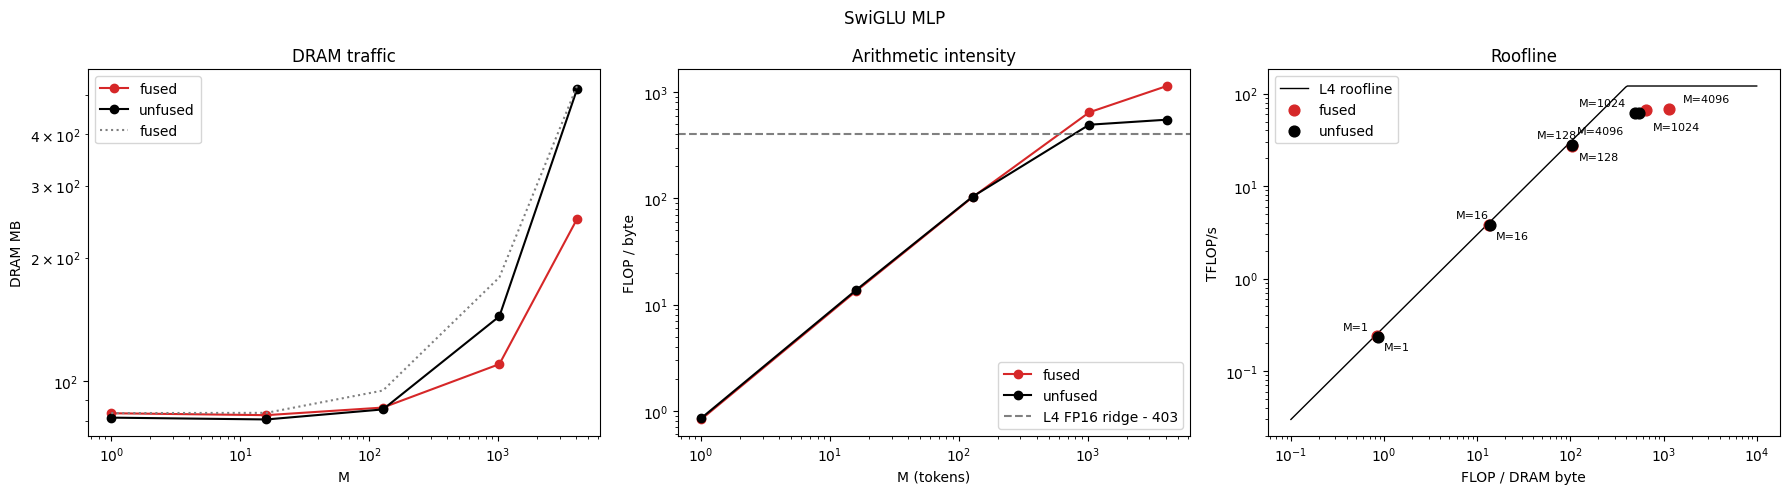

In [10]:
import numpy as np
import matplotlib.pyplot as plt

PEAK_TFLOPS = 121
BW_GBS = 300
RIDGE = PEAK_TFLOPS * 1e12 / (BW_GBS * 1e9)

COL = {"unfused": "black", "fused": "tab:red"}

Ms = np.array(sorted(results.M.unique()))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))


ax = axes[0]

for impl, g in results.groupby("impl"):
    ax.plot(g.M, g.dram_MB, "o-", color=COL[impl], label=impl)

ax.plot(Ms, [pivot.loc[m, "fused"] + expected[m] for m in Ms], ":", color="gray",
        label="fused")

ax.set(xscale="log", yscale="log", xlabel="M", ylabel="DRAM MB",
       title="DRAM traffic")
ax.legend()

ax = axes[1]

for impl, g in results.groupby("impl"):
    ax.plot(g.M, g.AI_dram, "o-", color=COL[impl], label=impl)

ax.axhline(RIDGE, color="gray", ls="--", label=f"L4 FP16 ridge - {RIDGE:.0f}")

ax.set(xscale="log", yscale="log", xlabel="M (tokens)", ylabel="FLOP / byte",
       title="Arithmetic intensity")

ax.legend()

ax = axes[2]
ai = np.logspace(-1, 4, 300)

ax.plot(ai, np.minimum(PEAK_TFLOPS, ai * BW_GBS / 1e3), "k-", lw=1, label="L4 roofline")

for impl, g in results.groupby("impl"):
    ax.scatter(g.AI_dram, g.tflops, color=COL[impl], s=60, label=impl, zorder=3)

    for _, r in g.iterrows():
        m_val = int(r.M)
        if impl == "unfused":
            if m_val == 1024:
                xytext = (-40, 5)
            elif m_val == 4096:
                xytext = (-45, -15)
            else:
                xytext = (-25, 5)
        else:
            if m_val == 1024:
                xytext = (5, -15)
            elif m_val == 4096:
                xytext = (10, 5)
            else:
                xytext = (5, -10)

        ax.annotate(f"M={m_val}", (r.AI_dram, r.tflops), fontsize=8,
                    xytext=xytext, textcoords="offset points")

ax.set(xscale="log", yscale="log", xlabel="FLOP / DRAM byte", ylabel="TFLOP/s", title="Roofline")

ax.legend()

fig.suptitle("SwiGLU MLP")
fig.tight_layout()
plt.savefig("swiglu_ncu.png", dpi=200, bbox_inches="tight")
plt.show()